# Week 2 — Data Preparation and Baseline
## Voice-based screening of Parkinson's disease (UCI dataset 470)

Plan of this notebook (Week 2 deliverable: clean dataset, baseline implementation, initial results):
1. Load and clean the raw data, with every decision written down.
2. Create the **subject-level** train / test split once and save it (`data/processed/split.csv`).
3. Implement the baselines: majority-class dummy, gender-only model, logistic regression on all features.
4. Evaluate them with **5-fold StratifiedGroupKFold repeated over 3 seeds** on the training subjects only.
5. Leakage check: grouped vs non-grouped CV.

**The test subjects are not used anywhere in this notebook.** They are only evaluated once, in Week 4.

### Running on Google Colab
Locally this cell does nothing. On Colab it clones the project repo so that the relative paths (`../data/...`, `../results/...`) work.
**Set `REPO_URL` to your group's GitHub repo** (it must be public).

In [1]:
import os, sys, subprocess

REPO_URL = "https://github.com/AA-ESILV/ML-FINALPROJECT-pd-voice-screening.git"

if "google.colab" in sys.modules:
    repo_dir = "/content/" + REPO_URL.rstrip("/").split("/")[-1].removesuffix(".git")
    if not os.path.isdir(repo_dir):
        subprocess.run(["git", "clone", "-q", REPO_URL, repo_dir], check=True)
    os.chdir(repo_dir + "/notebooks")
    print("Working directory:", os.getcwd())

### ▶ Setup — works on your computer **and** in Google Colab
In Colab, this cell clones the project repo (data included) and moves into `notebooks/`.
If the repo is not set or is private, it asks you to upload `pd_speech_features.csv` instead.
On your own computer it does nothing.

In [2]:
import os, sys, subprocess
from pathlib import Path

REPO_URL = "https://github.com/<your-username>/pd-voice-screening.git"   # <- put your repo URL here (public repo)
RAW_NAME = "pd_speech_features.csv"

if "google.colab" in sys.modules:
    repo_dir = Path("/content") / REPO_URL.rstrip("/").split("/")[-1].removesuffix(".git")
    if "<your-username>" not in REPO_URL and not repo_dir.exists():
        subprocess.run(["git", "clone", "--depth", "1", REPO_URL, str(repo_dir)], check=False)
    if (repo_dir / "notebooks").exists():
        os.chdir(repo_dir / "notebooks")
    else:  # no repo available: build the folders and upload the CSV by hand
        work = Path("/content/project")
        for d in ["notebooks", "data/raw", "data/processed", "results"]:
            (work / d).mkdir(parents=True, exist_ok=True)
        os.chdir(work / "notebooks")
        raw = work / "data" / "raw" / RAW_NAME
        if not raw.exists():
            from google.colab import files
            print(f"Please upload {RAW_NAME} (UCI dataset 470).")
            uploaded = files.upload()
            raw.write_bytes(next(iter(uploaded.values())))

Path("../results").mkdir(exist_ok=True)
print("Working directory:", Path.cwd())

Working directory: /home/claude/proj/notebooks


In [3]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, StratifiedGroupKFold, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (roc_auc_score, recall_score, balanced_accuracy_score,
                             f1_score, accuracy_score, confusion_matrix)

ROOT = Path("..")                       # notebook lives in notebooks/
RAW = ROOT / "data" / "raw" / "pd_speech_features.csv"
PROC = ROOT / "data" / "processed"
RES = ROOT / "results"
PROC.mkdir(parents=True, exist_ok=True); RES.mkdir(exist_ok=True)

RANDOM_STATE = 42
CV_SEEDS = [0, 1, 2]
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

## 1. Load the raw data

In [4]:
df = pd.read_csv(RAW)
if df.columns[0] != "id":              # the UCI file has an extra header line with group names
    df = pd.read_csv(RAW, header=1)
print("Raw shape:", df.shape)

Raw shape: (756, 755)


## 2. Cleaning and integrity checks
Each check is an `assert`: if the data ever changes (new download, other mirror), the notebook stops instead of silently producing wrong results.

In [5]:
feature_cols = [c for c in df.columns if c not in ("id", "class")]

# 2.1 types and target
assert df["class"].isin([0, 1]).all(), "class must be binary"
assert df["gender"].isin([0, 1]).all(), "gender must be binary (1 = male)"
assert all(np.issubdtype(df[c].dtype, np.number) for c in feature_cols), "all features numeric"

# 2.2 missing and infinite values
n_missing = int(df.isna().sum().sum())
n_inf = int(np.isinf(df[feature_cols].to_numpy()).sum())
print("Missing values:", n_missing, "| infinite values:", n_inf)
assert n_missing == 0 and n_inf == 0

# 2.3 subject structure
per_subject = df.groupby("id").size()
assert (per_subject == 3).all(), "each subject should have 3 recordings"
assert (df.groupby("id")["class"].nunique() == 1).all(), "label constant within subject"
assert (df.groupby("id")["gender"].nunique() == 1).all(), "gender constant within subject"
print("Subjects:", df["id"].nunique(), "| recordings:", len(df))

# 2.4 constant columns
const = [c for c in feature_cols if df[c].nunique() <= 1]
print("Constant columns:", const)

# 2.5 exact duplicates
dup_mask = df.drop(columns="id").duplicated(keep=False)
print("Duplicated recordings belong to subject(s):", df.loc[dup_mask, "id"].unique().tolist())

Missing values: 0 | infinite values: 0
Subjects: 252 | recordings: 756
Constant columns: []
Duplicated recordings belong to subject(s): [37]


**Cleaning decisions**

| Check | Result | Decision | Why |
|---|---|---|---|
| Missing / infinite values | 0 / 0 | No imputation | Nothing to impute |
| Constant columns | none | Keep all 753 features | Removal of uninformative features is part of Week 3 feature selection, done inside CV |
| Duplicate recording | 1 (subject 37) | Keep | Both copies belong to the same subject, so the subject split keeps them together: no leakage. Removing it would leave subject 37 with 2 recordings instead of 3 |
| Extreme values (\|z\| > 5 in 373 recordings, Week 1) | signal-derived measures | Keep | *Outlier ≠ error* (Lesson 1): no physical range is violated, and we have no ground truth to correct them |
| Scales from 1e-20 to 1e10 | — | `StandardScaler` **inside** the pipeline | Fit on training folds only (Lesson 1, rule 2) |
| `id` column | subject identifier | Never a feature; used only as `groups` | Using it as input would let the model memorise people |

Nothing is fitted on the data at this stage, so the clean file can safely be shared by all team members.

In [6]:
clean = df.copy()
clean.to_csv(PROC / "pd_speech_clean.csv", index=False)
print("Saved", PROC / "pd_speech_clean.csv", clean.shape)

Saved ../data/processed/pd_speech_clean.csv (756, 755)


## 3. Subject-level train / test split (done once, then frozen)
We split the **252 subject ids**, not the 756 rows. We stratify on *class × gender*, so both classes and the gender confounder have the same proportions in train and test.

In [7]:
subjects = clean.groupby("id").agg(cls=("class", "first"), gender=("gender", "first")).reset_index()
strata = subjects["cls"].astype(str) + "_" + subjects["gender"].astype(str)

train_ids, test_ids = train_test_split(subjects["id"], test_size=0.20,
                                       stratify=strata, random_state=RANDOM_STATE)
split = subjects.assign(split=np.where(subjects["id"].isin(test_ids), "test", "train"))
split[["id", "split"]].to_csv(PROC / "split.csv", index=False)

assert set(train_ids).isdisjoint(test_ids)
summary = (split.groupby("split")
                .agg(subjects=("id", "size"), PD=("cls", "sum"),
                     pct_PD=("cls", "mean"), pct_male=("gender", "mean")))
summary["recordings"] = summary["subjects"] * 3
summary["healthy"] = summary["subjects"] - summary["PD"]
summary[["subjects", "recordings", "PD", "healthy", "pct_PD", "pct_male"]].round(3)

,subjects,recordings,PD,healthy,pct_PD,pct_male
split,,,,,,
test,51,153,38,13,0.745,0.529
train,201,603,150,51,0.746,0.512


In [8]:
train = clean[clean["id"].isin(train_ids)].reset_index(drop=True)
X = train[feature_cols]
y = train["class"].to_numpy()
groups = train["id"].to_numpy()
print("Training recordings:", X.shape, "| training subjects:", len(np.unique(groups)))
# From here on, only `train` is used. `test_ids` is not touched again until Week 4.

Training recordings: (603, 753) | training subjects: 201


**Validation set:** with only ~200 training subjects, a single fixed validation set would be too small and too noisy (Lesson 2: small *n* → high variance). Each fold of a 5-fold `StratifiedGroupKFold` plays the role of the validation set in turn (about 40 subjects / 120 recordings), and we repeat it with 3 seeds.

## 4. Baseline models
- **B0 — majority class** (`DummyClassifier(strategy="most_frequent")`): the floor.
- **B1 — gender only** (logistic regression on `gender` alone): how much a shortcut on the confounder already gives.
- **B2 — logistic regression, all 753 features**: `StandardScaler → LogisticRegression(class_weight="balanced")`, default `C=1`. This is our reference model for Week 3.

In [9]:
def make_models():
    return {
        "B0 Majority class": Pipeline([("clf", DummyClassifier(strategy="most_frequent"))]),
        "B1 Gender only": Pipeline([("select", "passthrough"),
                                    ("clf", LogisticRegression(class_weight="balanced"))]),
        "B2 LogReg all features": Pipeline([("scale", StandardScaler()),
                                            ("clf", LogisticRegression(class_weight="balanced",
                                                                       max_iter=5000))]),
    }
COLS_FOR = {"B1 Gender only": ["gender"]}

### Evaluation function
For each fold we compute the metrics at two levels:
- **recording level**: one prediction per recording;
- **subject level**: the 3 probabilities of a person are averaged → one decision per person (the clinical unit).

Threshold = 0.5. Positive class = PD (1). Specificity = recall of the healthy class.

In [10]:
def metrics(y_true, proba, thr=0.5):
    pred = (proba >= thr).astype(int)
    auc = roc_auc_score(y_true, proba) if len(np.unique(proba)) > 1 else 0.5
    return {"ROC-AUC": auc,
            "Recall PD": recall_score(y_true, pred, pos_label=1),
            "Specificity": recall_score(y_true, pred, pos_label=0),
            "Balanced acc.": balanced_accuracy_score(y_true, pred),
            "F1 (PD)": f1_score(y_true, pred, pos_label=1),
            "Accuracy": accuracy_score(y_true, pred)}

def to_subject(ids, y_true, proba):
    s = pd.DataFrame({"id": ids, "y": y_true, "p": proba}).groupby("id").mean()
    return s["y"].to_numpy().astype(int), s["p"].to_numpy()

def evaluate(model_name, splitter_factory, use_groups=True, seeds=CV_SEEDS):
    rows, oof = [], []
    cols = COLS_FOR.get(model_name, feature_cols)
    for seed in seeds:
        cv = splitter_factory(seed)
        splits = cv.split(X, y, groups) if use_groups else cv.split(X, y)
        for fold, (tr, va) in enumerate(splits):
            model = make_models()[model_name]
            model.fit(X.iloc[tr][cols], y[tr])
            p_va = model.predict_proba(X.iloc[va][cols])[:, 1]
            p_tr = model.predict_proba(X.iloc[tr][cols])[:, 1]
            for level, (yt, pt) in {"recording": (y[va], p_va),
                                    "subject": to_subject(groups[va], y[va], p_va)}.items():
                rows.append({"model": model_name, "seed": seed, "fold": fold, "set": "validation",
                             "level": level, **metrics(yt, pt)})
            ys_tr, ps_tr = to_subject(groups[tr], y[tr], p_tr)
            rows.append({"model": model_name, "seed": seed, "fold": fold, "set": "train",
                         "level": "subject", **metrics(ys_tr, ps_tr)})
            if seed == seeds[0]:
                oof.append(pd.DataFrame({"id": groups[va], "y": y[va], "p": p_va, "model": model_name}))
    return pd.DataFrame(rows), pd.concat(oof)

grouped_cv = lambda seed: StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=seed)

In [11]:
results, oofs = [], []
for name in make_models():
    r, o = evaluate(name, grouped_cv)
    results.append(r); oofs.append(o)
results = pd.concat(results, ignore_index=True)
oofs = pd.concat(oofs, ignore_index=True)
results.to_csv(RES / "week2_cv_results.csv", index=False)

METRICS = ["ROC-AUC", "Recall PD", "Specificity", "Balanced acc.", "F1 (PD)", "Accuracy"]
def table(level, set_="validation"):
    t = results.query("level == @level and set == @set_").groupby("model")[METRICS]
    return (t.mean().round(3).astype(str) + " ± " + t.std().round(3).astype(str))

print("SUBJECT LEVEL — validation folds (mean ± std over 5 folds × 3 seeds)")
display(table("subject"))
print("RECORDING LEVEL — validation folds")
display(table("recording"))

SUBJECT LEVEL — validation folds (mean ± std over 5 folds × 3 seeds)


,ROC-AUC,Recall PD,Specificity,Balanced acc.,F1 (PD),Accuracy
model,,,,,,
B0 Majority class,0.5 ± 0.0,1.0 ± 0.0,0.0 ± 0.0,0.5 ± 0.0,0.855 ± 0.005,0.746 ± 0.008
B1 Gender only,0.606 ± 0.078,0.567 ± 0.094,0.645 ± 0.154,0.606 ± 0.078,0.668 ± 0.072,0.587 ± 0.07
B2 LogReg all features,0.822 ± 0.064,0.871 ± 0.068,0.624 ± 0.162,0.747 ± 0.073,0.87 ± 0.037,0.808 ± 0.049


RECORDING LEVEL — validation folds


,ROC-AUC,Recall PD,Specificity,Balanced acc.,F1 (PD),Accuracy
model,,,,,,
B0 Majority class,0.5 ± 0.0,1.0 ± 0.0,0.0 ± 0.0,0.5 ± 0.0,0.855 ± 0.005,0.746 ± 0.008
B1 Gender only,0.606 ± 0.078,0.567 ± 0.094,0.645 ± 0.154,0.606 ± 0.078,0.668 ± 0.072,0.587 ± 0.07
B2 LogReg all features,0.791 ± 0.055,0.827 ± 0.052,0.607 ± 0.111,0.717 ± 0.056,0.843 ± 0.032,0.771 ± 0.043


### Overfitting check: training vs validation (subject level)

In [12]:
gap = (results.query("level == 'subject'")
              .groupby(["model", "set"])[["ROC-AUC", "Balanced acc."]].mean().round(3).unstack("set"))
gap

ROC-AUC            Balanced acc.           
set                      train validation         train validation
model                                                             
B0 Majority class        0.500      0.500         0.500      0.500
B1 Gender only           0.607      0.606         0.607      0.606
B2 LogReg all features   1.000      0.822         1.000      0.747

### Subject-level confusion matrix of B2 (out-of-fold predictions, seed 0)

In [13]:
o = oofs.query("model == 'B2 LogReg all features'")
ys, ps = to_subject(o["id"].to_numpy(), o["y"].to_numpy(), o["p"].to_numpy())
cm = confusion_matrix(ys, (ps >= 0.5).astype(int), labels=[0, 1])
cm_df = pd.DataFrame(cm, index=["True healthy", "True PD"], columns=["Pred healthy", "Pred PD"])
cm_df.to_csv(RES / "week2_confusion_B2.csv")
cm_df

,Pred healthy,Pred PD
True healthy,31,20
True PD,21,129


### Per-gender recall of B2 (is the model only learning gender?)

In [14]:
g = train.groupby("id")["gender"].first()
o_sub = o.groupby("id").agg(y=("y", "first"), p=("p", "mean")).join(g)
o_sub["pred"] = (o_sub["p"] >= 0.5).astype(int)
per_gender = (o_sub.groupby("gender")
                   .apply(lambda d: pd.Series({"subjects": len(d),
                                               "Recall PD": recall_score(d.y, d.pred, pos_label=1, zero_division=0),
                                               "Specificity": recall_score(d.y, d.pred, pos_label=0, zero_division=0)}),
                          include_groups=False)
                   .rename(index={0: "Female", 1: "Male"}).round(3))
per_gender

,subjects,Recall PD,Specificity
gender,,,
Female,98.0,0.862,0.667
Male,103.0,0.859,0.500


## 5. Leakage check: grouped vs non-grouped CV
Same models, same data, but a plain `StratifiedKFold` on **recordings**: the 3 recordings of a person can end up on both sides of a fold. We add a 1-nearest-neighbour model as a probe: it can only score well by finding the same person's voice.

In [15]:
leak_models = {
    "B2 LogReg all features": lambda: make_models()["B2 LogReg all features"],
    "Probe 1-NN": lambda: Pipeline([("scale", StandardScaler()), ("clf", KNeighborsClassifier(n_neighbors=1))]),
}
leak_rows = []
for name, factory in leak_models.items():
    for scheme, cv_f, use_g in [("Grouped (by subject)", grouped_cv, True),
                                ("Not grouped (by recording)",
                                 lambda s: StratifiedKFold(5, shuffle=True, random_state=s), False)]:
        for seed in CV_SEEDS:
            cv = cv_f(seed)
            for tr, va in (cv.split(X, y, groups) if use_g else cv.split(X, y)):
                m = factory().fit(X.iloc[tr], y[tr])
                p = m.predict_proba(X.iloc[va])[:, 1]
                leak_rows.append({"model": name, "scheme": scheme,
                                  "Balanced acc.": balanced_accuracy_score(y[va], (p >= 0.5).astype(int)),
                                  "ROC-AUC": roc_auc_score(y[va], p)})
leak = pd.DataFrame(leak_rows)
leak.to_csv(RES / "week2_leakage_check.csv", index=False)
leak_tab = leak.groupby(["model", "scheme"])[["Balanced acc.", "ROC-AUC"]].agg(["mean", "std"]).round(3)
leak_tab

Balanced acc.         \
                                                           mean    std   
model                  scheme                                            
B2 LogReg all features Grouped (by subject)               0.717  0.056   
                       Not grouped (by recording)         0.799  0.038   
Probe 1-NN             Grouped (by subject)               0.693  0.051   
                       Not grouped (by recording)         0.880  0.037   

                                                  ROC-AUC         
                                                     mean    std  
model                  scheme                                     
B2 LogReg all features Grouped (by subject)         0.791  0.055  
                       Not grouped (by recording)   0.884  0.034  
Probe 1-NN             Grouped (by subject)         0.693  0.051  
                       Not grouped (by recording)   0.880  0.037

## 6. Figures

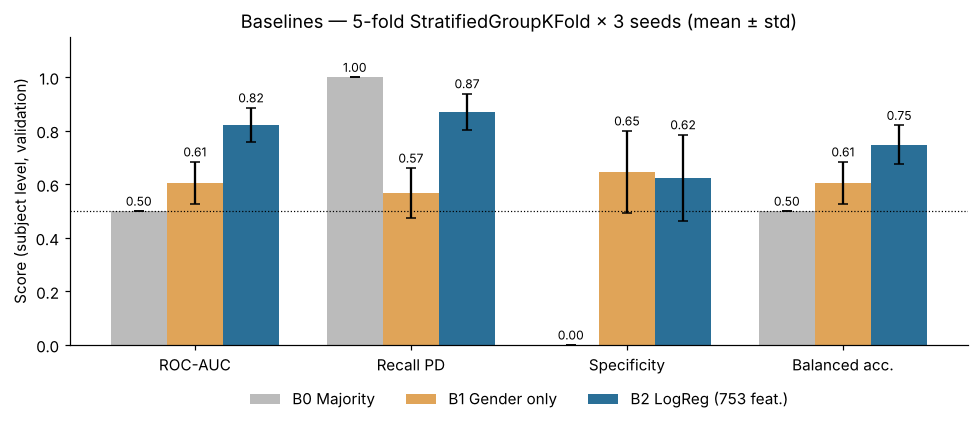

In [16]:
order = ["B0 Majority class", "B1 Gender only", "B2 LogReg all features"]
short = {"B0 Majority class": "B0 Majority", "B1 Gender only": "B1 Gender only",
         "B2 LogReg all features": "B2 LogReg (753 feat.)"}
show = ["ROC-AUC", "Recall PD", "Specificity", "Balanced acc."]
sub = results.query("level == 'subject' and set == 'validation'")
mean = sub.groupby("model")[show].mean().loc[order]
std = sub.groupby("model")[show].std().loc[order]

fig, ax = plt.subplots(figsize=(9, 4))
w = 0.26; x = np.arange(len(show))
colors = ["#BBBBBB", "#E0A458", "#2A6F97"]
for i, m in enumerate(order):
    ax.bar(x + (i - 1) * w, mean.loc[m], w, yerr=std.loc[m], capsize=3, color=colors[i], label=short[m])
    for j, v in enumerate(mean.loc[m]):
        ax.text(x[j] + (i - 1) * w, v + std.loc[m].iloc[j] + 0.02, f"{v:.2f}", ha="center", fontsize=8)
ax.axhline(0.5, color="black", lw=0.8, ls=":")
ax.set_xticks(x); ax.set_xticklabels(show); ax.set_ylim(0, 1.15)
ax.set_ylabel("Score (subject level, validation)")
ax.set_title("Baselines — 5-fold StratifiedGroupKFold × 3 seeds (mean ± std)")
ax.legend(frameon=False, ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.1))
plt.tight_layout(); plt.savefig(RES / "fig5_baselines.png", bbox_inches="tight"); plt.show()

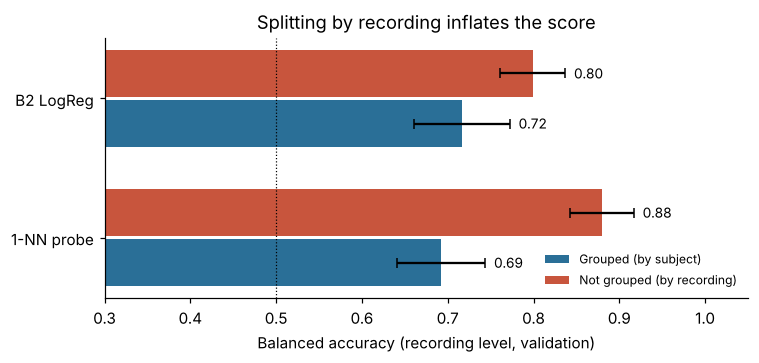

In [17]:
lt = leak.groupby(["model", "scheme"])["Balanced acc."].agg(["mean", "std"]).reset_index()
fig, ax = plt.subplots(figsize=(7, 3.4))
models_ = ["Probe 1-NN", "B2 LogReg all features"]
schemes = ["Grouped (by subject)", "Not grouped (by recording)"]
cols = {"Grouped (by subject)": "#2A6F97", "Not grouped (by recording)": "#C8553D"}
for i, m in enumerate(models_):
    for k, s in enumerate(schemes):
        r = lt[(lt.model == m) & (lt.scheme == s)].iloc[0]
        yv = i + (k - 0.5) * 0.36
        ax.barh(yv, r["mean"], 0.34, xerr=r["std"], capsize=3, color=cols[s], label=s if i == 0 else None)
        ax.text(r["mean"] + r["std"] + 0.01, yv, f"{r['mean']:.2f}", va="center", fontsize=9)
ax.set_yticks(range(len(models_))); ax.set_yticklabels(["1-NN probe", "B2 LogReg"])
ax.axvline(0.5, color="black", lw=0.8, ls=":")
ax.set_xlim(0.3, 1.05); ax.set_xlabel("Balanced accuracy (recording level, validation)")
ax.set_title("Splitting by recording inflates the score")
ax.legend(frameon=False, loc="lower right", fontsize=8)
plt.tight_layout(); plt.savefig(RES / "fig6_leakage.png", bbox_inches="tight"); plt.show()

## 7. Conclusions for Week 2 (filled after running — see report)
- The data is clean; no row or column was removed.
- The split is frozen in `data/processed/split.csv` (subject ids → train/test).
- B2 is the reference that Week 3 models and feature selection must beat, **on the same grouped CV folds and seeds**.